In [2]:
pip install pandas numpy scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
print("Jupyter is working")

Jupyter is working


In [4]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = (
    r"C:\Users\dfern\Documents\GitHub\Marburg-Sem-I"
    r"\Forecasting Theory & Practical\Tutorial Exercises"
    r"\EX1\T2M_frankfurt_airport.csv"
)

# Show what is actually stored in the file
with open(file_path, "r", encoding="utf-8-sig") as f:
    print("Header:", repr(f.readline()))
    print("First data row:", repr(f.readline()))

# Detect the separator rather than assuming commas or spaces
df = pd.read_csv(
    file_path,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

df.columns = df.columns.str.strip().str.strip('"')

#print("\nColumns:", df.columns.tolist())
print("Shape before setting index:", df.shape)
print(df.head(5))

# Stop here with a useful message if parsing is still incorrect
if "time" not in df.columns:
    raise ValueError(
        "No separate 'time' column was found. "
        "Check the printed Header and Columns above."
    )

# The date 1/1/2016 alone does not distinguish day/month from month/day.
# Parse dates as month/day/year
df["time"] = pd.to_datetime(
    df["time"],
    format="%m/%d/%Y",
    errors="raise"
)

df = df.set_index("time").sort_index()

print("Date range:", df.index.min(), "to", df.index.max())

print("\nSuccessfully loaded:")
#print(df.head(5))

Header: 'time,obs,member_1,member_2,member_3,member_4,member_5,member_6,member_7,member_8,member_9,member_10,member_11,member_12,member_13,member_14,member_15,member_16,member_17,member_18,member_19,member_20,member_21,member_22,member_23,member_24,member_25,member_26,member_27,member_28,member_29,member_30,member_31,member_32,member_33,member_34,member_35,member_36,member_37,member_38,member_39,member_40,member_41,member_42,member_43,member_44,member_45,member_46,member_47,member_48,member_49,member_50\n'
First data row: '1/1/2016,5.199999809,1.923394799,-0.080633543,-1.043280005,0.801141381,2.440515041,-0.93952024,0.913354516,-0.658453345,4.377007961,-0.563940406,-0.962225318,0.541253686,-0.214392096,1.03011477,-6.10E-06,0.644921899,1.847558618,-1.733435035,1.03023684,5.314752102,0.307519525,2.634301662,-0.70538938,5.537774563,2.451928616,0.018121338,-0.278875738,1.237817407,2.204370022,3.909051418,4.317468166,-0.734747291,-0.046697997,0.259484857,-0.78415525,2.578485012,2.425378323,

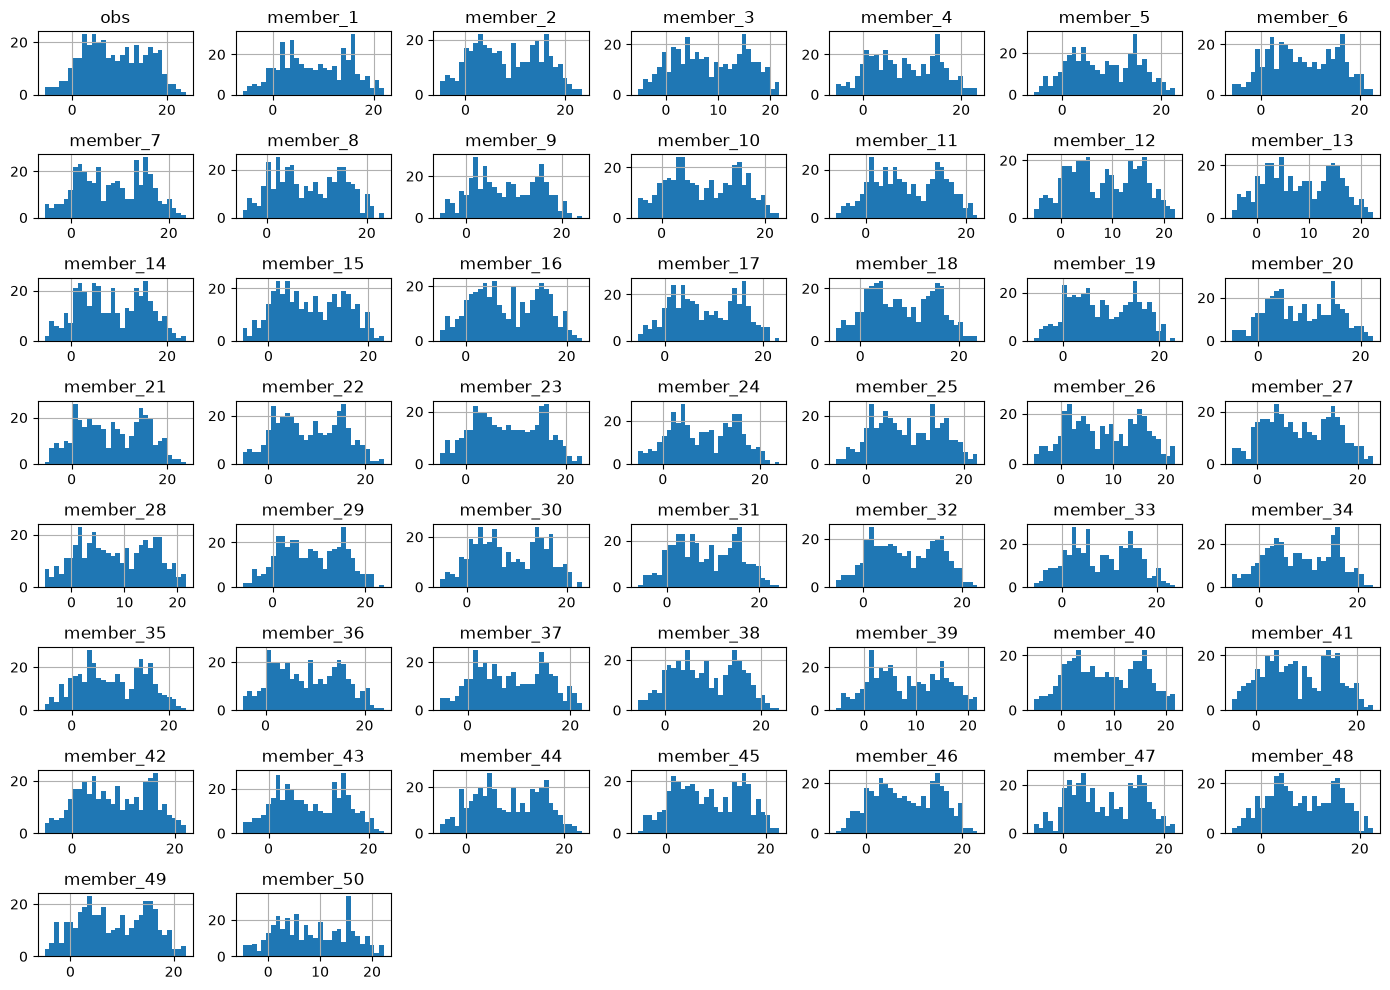

In [6]:
# Distribution of every numeric column
df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

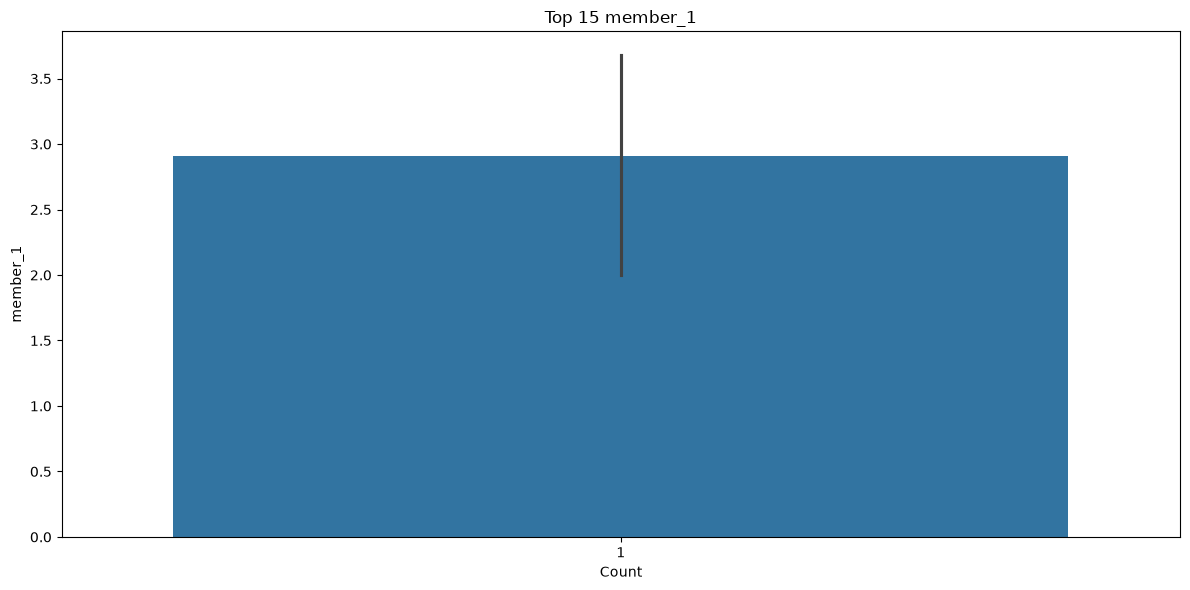

In [7]:
categorical_col = "member_1"

counts = df[categorical_col].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=counts.values, y=counts.index)
plt.title(f"Top 15 {categorical_col}")
plt.xlabel("Count")
plt.ylabel(categorical_col)
plt.tight_layout()
plt.show()

c:\Users\dfern\AppData\Local\Programs\Python\Python315\Lib\site-packages\pandas\plotting\_matplotlib\core.py:999: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


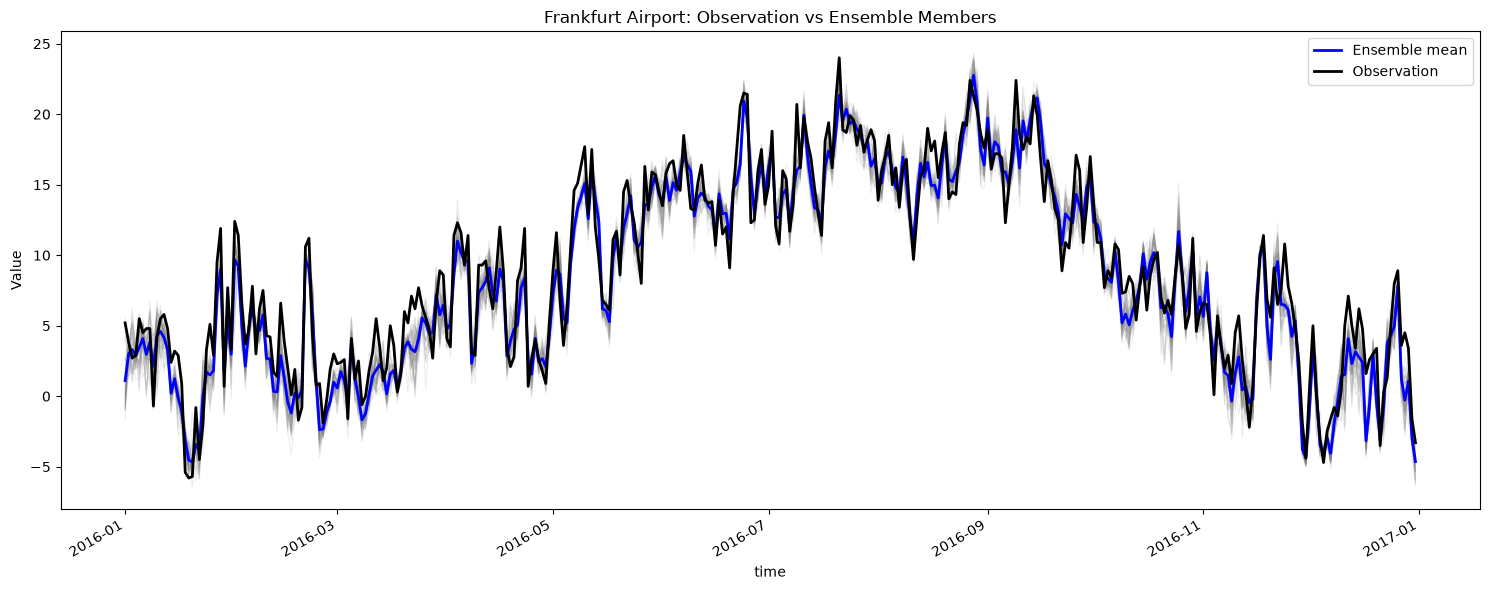

In [9]:
member_cols = [c for c in df.columns if c.startswith("member_")]

plt.figure(figsize=(15, 6))

for col in member_cols:
    plt.plot(df.index, df[col], color="gray", alpha=0.15, linewidth=0.8)

df[member_cols].mean(axis=1).plot(
    color="blue", linewidth=2, label="Ensemble mean"
)

df["obs"].plot(
    color="black", linewidth=2, label="Observation"
)

plt.title("Frankfurt Airport: Observation vs Ensemble Members")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

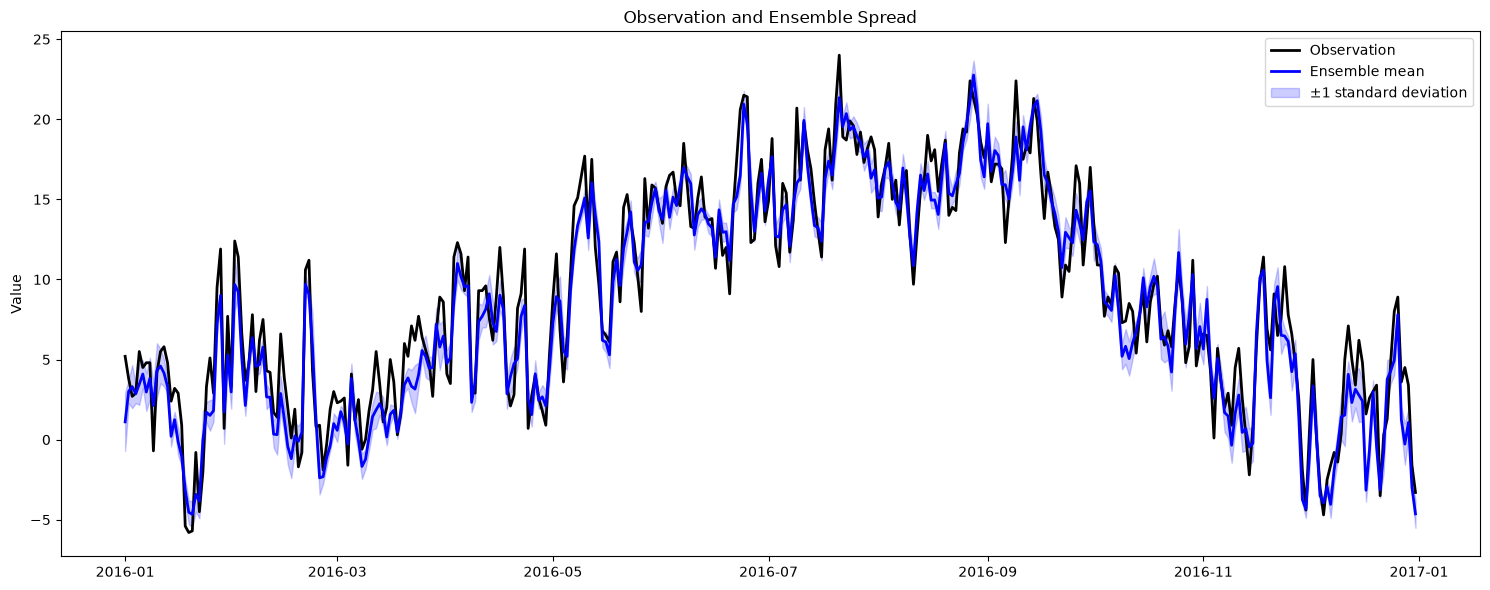

In [10]:
ensemble_mean = df[member_cols].mean(axis=1)
ensemble_std = df[member_cols].std(axis=1)

plt.figure(figsize=(15, 6))

plt.plot(df.index, df["obs"], color="black", linewidth=2, label="Observation")
plt.plot(df.index, ensemble_mean, color="blue", linewidth=2, label="Ensemble mean")

plt.fill_between(
    df.index,
    ensemble_mean - ensemble_std,
    ensemble_mean + ensemble_std,
    color="blue",
    alpha=0.2,
    label="±1 standard deviation"
)

plt.title("Observation and Ensemble Spread")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

#Distribution of one day’s forecast

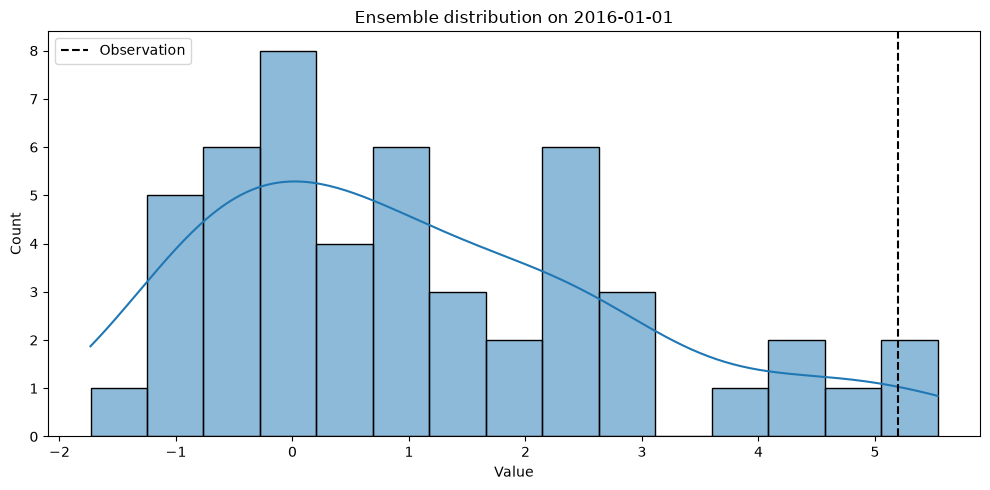

In [11]:
day = "2016-01-01"

plt.figure(figsize=(10, 5))
sns.histplot(df.loc[day, member_cols], bins=15, kde=True)
plt.axvline(df.loc[day, "obs"], color="black", linestyle="--", label="Observation")
plt.title(f"Ensemble distribution on {day}")
plt.xlabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

Monthly boxplot

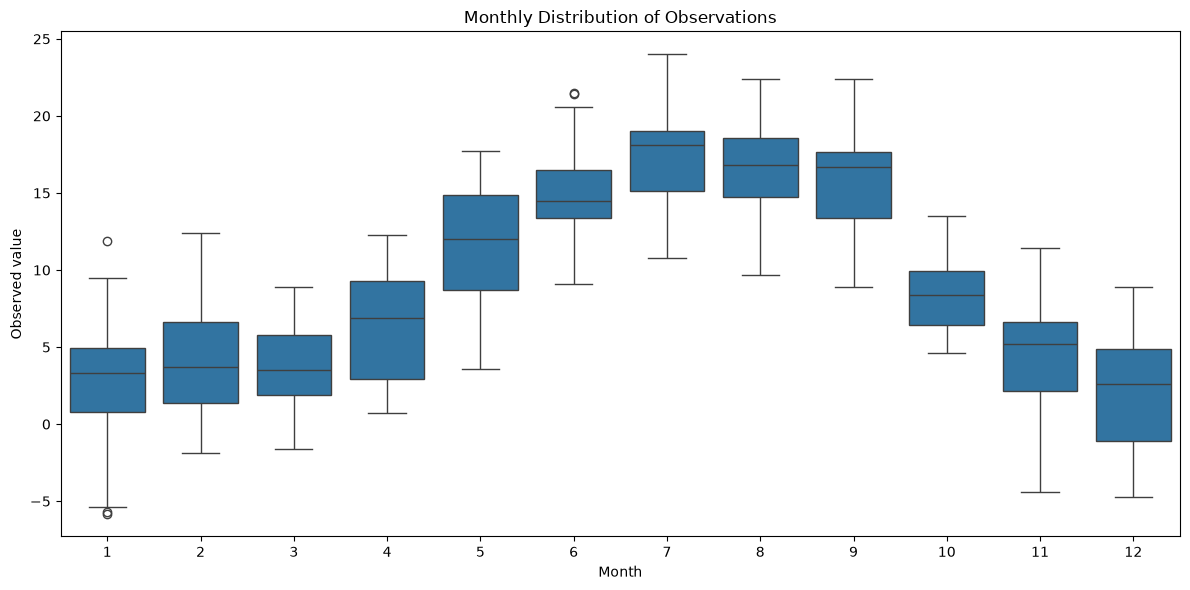

In [12]:
df["month"] = df.index.month

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="month", y="obs")
plt.title("Monthly Distribution of Observations")
plt.xlabel("Month")
plt.ylabel("Observed value")
plt.tight_layout()
plt.show()

df = df.drop(columns="month")

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.stats import norm

# 1. Load and validate the dataset

In [14]:
file_path = (
    r"C:\Users\dfern\Documents\GitHub\Marburg-Sem-I"
    r"\Forecasting Theory & Practical\Tutorial Exercises"
    r"\EX1\T2M_frankfurt_airport.csv"
)

df = pd.read_csv(
    file_path,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

df.columns = df.columns.str.strip().str.strip('"')

if "time" not in df.columns:
    raise ValueError(
        f"'time' column not found. Parsed columns: {df.columns.tolist()}"
    )

# Your edited file uses month/day/year.
df["time"] = pd.to_datetime(
    df["time"],
    format="%m/%d/%Y",
    errors="raise"
)

df = df.set_index("time").sort_index()

member_cols = [f"member_{i}" for i in range(1, 51)]
required_cols = ["obs"] + member_cols

missing = [col for col in required_cols if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df[required_cols].apply(pd.to_numeric, errors="raise")

if not np.isfinite(df.to_numpy()).all():
    raise ValueError("Dataset contains missing or infinite values.")

if df.index.has_duplicates:
    raise ValueError("Dataset contains duplicate dates.")

# 2. Ensemble predictors and chronological split

In [15]:
df["ens_mean"] = df[member_cols].mean(axis=1)
df["ens_var"] = df[member_cols].var(axis=1, ddof=1)

train = df.loc["2016-01-01":"2016-09-30"].copy()
test = df.loc["2016-10-01":"2016-12-31"].copy()

if train.empty or test.empty:
    raise ValueError("Training or test period is empty. Check date parsing.")

print(f"Training cases: {len(train)}")
print(f"Test cases:     {len(test)}")

y_train = train["obs"].to_numpy()
x_train = train["ens_mean"].to_numpy()
s2_train = train["ens_var"].to_numpy()

# --------------------------------------------------
# 3. Gaussian negative log-likelihood

def negative_log_likelihood(theta):
    a, b, c, d = theta

    mu = a + b * x_train
    variance = c + d * s2_train

    if np.any(variance <= 0):
        return np.inf

    residual = y_train - mu

    return 0.5 * np.sum(
        np.log(2 * np.pi)
        + np.log(variance)
        + residual**2 / variance
    )

# Initial mean parameters from ordinary least squares.
design = np.column_stack([np.ones(len(train)), x_train])
a0, b0 = np.linalg.lstsq(design, y_train, rcond=None)[0]

residual_variance = max(
    np.mean((y_train - (a0 + b0 * x_train))**2),
    1e-6
)

mean_ensemble_variance = max(np.mean(s2_train), 1e-8)

# Multiple starting values reduce dependence on one initialization.
starts = [
    [a0, b0, residual_variance, 0.0],
    [a0, b0, 0.5 * residual_variance,
     0.5 * residual_variance / mean_ensemble_variance],
    [a0, b0, 0.1 * residual_variance,
     0.9 * residual_variance / mean_ensemble_variance],
    [0.0, 1.0, 0.1, 1.0]
]

bounds = [
    (None, None),  # a
    (None, None),  # b
    (1e-8, None),  # c
    (0.0, None)   # d
]

fits = [
    minimize(
        negative_log_likelihood,
        x0=start,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 10000, "ftol": 1e-12}
    )
    for start in starts
]

successful_fits = [
    fit for fit in fits if fit.success and np.isfinite(fit.fun)
]

if not successful_fits:
    raise RuntimeError(
        "Optimization failed:\n"
        + "\n".join(str(fit.message) for fit in fits)
    )

fit = min(successful_fits, key=lambda result: result.fun)
a_hat, b_hat, c_hat, d_hat = fit.x

parameters = pd.Series(
    fit.x,
    index=["a", "b", "c", "d"],
    name="MLE"
)

print("\nEstimated EMOS parameters:")
print(parameters.to_string(float_format=lambda value: f"{value:.6f}"))
print(f"\nTraining negative log-likelihood: {fit.fun:.4f}")

Training cases: 274
Test cases:     92

Estimated EMOS parameters:
a   1.039489
b   0.958278
c   1.358978
d   1.583828

Training negative log-likelihood: 510.1476


# 4. Test-period predictive distribution

In [ ]:
test["emos_mean"] = a_hat + b_hat * test["ens_mean"]
test["emos_var"] = c_hat + d_hat * test["ens_var"]
test["emos_sd"] = np.sqrt(test["emos_var"])

z = norm.ppf(0.95)

test["emos_lower"] = test["emos_mean"] - z * test["emos_sd"]
test["emos_upper"] = test["emos_mean"] + z * test["emos_sd"]

# Raw central empirical 90% interval.
test["raw_lower"] = test[member_cols].quantile(
    0.05, axis=1, interpolation="linear"
)
test["raw_upper"] = test[member_cols].quantile(
    0.95, axis=1, interpolation="linear"
)

# --------------------------------------------------
# 5. Coverage and interval widths
# --------------------------------------------------
def interval_summary(y, lower, upper):
    covered = (y >= lower) & (y <= upper)

    return {
        "Cases": len(y),
        "Covered": int(covered.sum()),
        "Coverage (%)": 100 * covered.mean(),
        "Mean width": (upper - lower).mean()
    }

comparison = pd.DataFrame({
    "Raw ensemble": interval_summary(
        test["obs"], test["raw_lower"], test["raw_upper"]
    ),
    "Gaussian EMOS": interval_summary(
        test["obs"], test["emos_lower"], test["emos_upper"]
    )
}).T

print("\nOctober–December interval comparison:")
print(comparison.round(4).to_string())

# Useful diagnostics for interpreting the parameters.
train_bias = (train["ens_mean"] - train["obs"]).mean()

mean_correction = (
    a_hat + (b_hat - 1) * train["ens_mean"]
).mean()

variance_ratio = (
    (c_hat + d_hat * train["ens_var"]).mean()
    / train["ens_var"].mean()
)

print("\nTraining diagnostics:")
print(f"Raw mean bias (forecast - observation): {train_bias:.4f}")
print(f"Average EMOS mean adjustment:           {mean_correction:.4f}")
print(f"Mean EMOS / mean raw variance:          {variance_ratio:.4f}")

# Each test case, including both prediction intervals.
print("\nFirst five test forecasts:")
print(
    test[
        ["obs", "emos_mean", "emos_sd",
         "emos_lower", "emos_upper",
         "raw_lower", "raw_upper"]
    ].head().round(4)
)


October–December interval comparison:
               Cases  Covered  Coverage (%)  Mean width
Raw ensemble    92.0     50.0       54.3478      2.8304
Gaussian EMOS   92.0     83.0       90.2174      5.5006

Training diagnostics:
Raw mean bias (forecast - observation): -0.5783
Average EMOS mean adjustment:           0.6301
Mean EMOS / mean raw variance:          3.3991

First five test forecasts:
             obs  emos_mean  emos_sd  emos_lower  emos_upper  raw_lower  \
time                                                                      
2016-10-01  13.5    12.8743   1.8969      9.7543     15.9944    10.5373   
2016-10-02  10.9    12.7084   1.3582     10.4744     14.9425    11.4639   
2016-10-03  10.9    11.7311   1.5339      9.2080     14.2542    10.0226   
2016-10-04   7.7     9.3051   1.4690      6.8889     11.7213     7.3707   
2016-10-05   8.9     9.0582   1.4198      6.7229     11.3935     7.5959   

            raw_upper  
time                   
2016-10-01    14.1942  
20

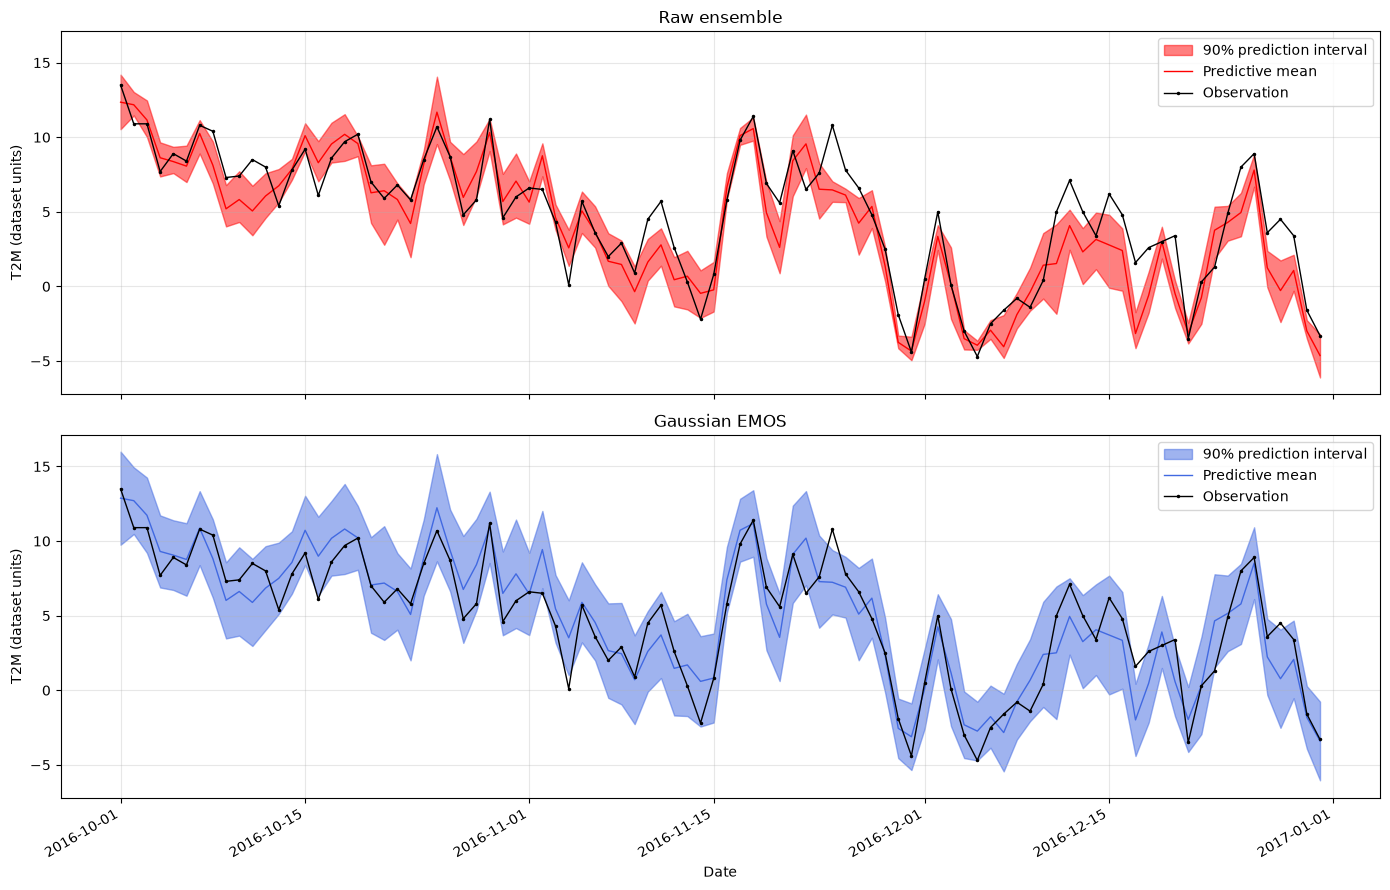

In [20]:
fig, axes = plt.subplots(
    2, 1, figsize=(14, 9), sharex=True, sharey=True
)

plots = [
    (
        axes[0], "Raw ensemble",
        "ens_mean", "raw_lower", "raw_upper", "red"
    ),
    (
        axes[1], "Gaussian EMOS",
        "emos_mean", "emos_lower", "emos_upper", "royalblue"
    )
]

for ax, title, mean_col, lower_col, upper_col, color in plots:
    ax.fill_between(
        test.index,
        test[lower_col].to_numpy(),
        test[upper_col].to_numpy(),
        color=color,
        alpha=0.50,
        label="90% prediction interval"
    )

    ax.plot(
        test.index, test[mean_col],
        color=color, linewidth=1.0, label="Predictive mean"
    )

    ax.plot(
        test.index, test["obs"],
        color="black", linewidth=1,
        marker=".", markersize=3, label="Observation"
    )

    ax.set_title(title)
    ax.set_ylabel("T2M (dataset units)")
    ax.grid(alpha=0.30)
    ax.legend(loc="best")

axes[-1].set_xlabel("Date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()